# Phân cụm khách hàng bằng K-Means trên RFM — Olist Data Warehouse (Team 7)

**Input:** `main_mart.mart_customer_rfm` trên MotherDuck, 3 đặc trưng `recency_days`, `frequency`, `monetary` (1 dòng / khách có ≥ 1 đơn delivered).
Review và giao hàng lấy từ `main_mart.mart_customer_360` **chỉ để mô tả cụm**, không đưa vào mô hình.

**Output (schema `ml` trên MotherDuck):** `ml.customer_cluster` (gán khách vào cụm), `ml.cluster_profile` (chân dung, nhãn, mô tả cụm), `ml.kmeans_model_selection` (đánh giá K). dbt đọc lại hai bảng đầu để dựng `mart_customer_rfm.cluster_id` và `dim_customer_cluster`.

**Thứ tự chạy:** `dbt build` mart_customer_360 + mart_customer_rfm → notebook này → `dbt build` mart_customer_rfm + dim_customer_cluster.

Notebook là nguồn duy nhất sinh kết quả phân cụm; chạy lại cho cùng kết quả nhờ `random_state` cố định.

In [1]:
import os
import sys
from datetime import datetime
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from dotenv import load_dotenv
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

# ---- Cấu hình cố định ----
RANDOM_STATE = 42
FEATURE_SET_VERSION = "rfm_v1"
K_RANGE = range(2, 11)          # đánh giá K = 2..10
K_CHOICE_RANGE = (3, 8)         # chỉ chọn K trong 3..8
MIN_CLUSTER_PCT = 2.0           # loại K có cụm nhỏ hơn 2% dân số
SIL_SAMPLE = 10_000             # silhouette tính trên mẫu (O(n^2))
N_INIT = 10
ARI_THRESHOLD = 0.90
RFM_TABLE = "main_mart.mart_customer_rfm"
C360_TABLE = "main_mart.mart_customer_360"
OUT_SCHEMA = "ml"
EXPECTED_ROWS = 93_358

NB_DIR = Path.cwd()
REPO_DIR = NB_DIR.parent if NB_DIR.name == "notebooks" else NB_DIR
FIG_DIR = REPO_DIR / "docs" / "figures" / "ml"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid")

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("duckdb      :", duckdb.__version__)
print("scikit-learn:", sklearn.__version__)
print("Thư mục hình:", FIG_DIR)

Python      : 3.13.1
pandas      : 3.1.0
duckdb      : 1.5.6
scikit-learn: 1.9.1
Thư mục hình: E:\UEL\Data-Warehouse\docs\figures\ml


## Bước 1 — Đọc dữ liệu và kiểm tra đầu vào
Kết nối MotherDuck bằng token trong `.env`. Không có token hoặc thiếu bảng thì dừng ngay, không dùng dữ liệu thay thế.

In [2]:
load_dotenv(REPO_DIR / ".env")
test_db = os.getenv("ML_TEST_DUCKDB")  # chỉ dùng khi kiểm thử code, để trống khi chạy thật
if test_db:
    con = duckdb.connect(test_db)
    print("[TEST MODE] dùng", test_db)
else:
    token = os.getenv("MOTHERDUCK_TOKEN")
    db_name = os.getenv("MOTHERDUCK_DATABASE", "olist_warehouse")
    if not token:
        raise RuntimeError("Không tìm thấy MOTHERDUCK_TOKEN trong .env")
    con = duckdb.connect(f"md:{db_name}", config={"motherduck_token": token})
    print("Đã kết nối MotherDuck:", con.execute("SELECT current_database()").fetchone()[0])

df = con.execute(f"""
    SELECT r.customer_unique_id, r.recency_days, r.frequency, r.monetary,
           c.avg_review_score, c.orders_on_time, c.orders_late, c.latest_state
    FROM {RFM_TABLE} r
    LEFT JOIN {C360_TABLE} c USING (customer_unique_id)
    ORDER BY r.customer_unique_id
""").df()

for col in ["recency_days", "frequency", "monetary", "avg_review_score", "orders_on_time", "orders_late"]:
    df[col] = pd.to_numeric(df[col]).astype(float)

assert len(df) == EXPECTED_ROWS, f"Số dòng {len(df):,} khác {EXPECTED_ROWS:,}"
assert df["customer_unique_id"].is_unique, "customer_unique_id bị trùng"
assert df[["recency_days", "frequency", "monetary"]].notna().all().all(), "R/F/M có giá trị NULL"
# Ngày tham chiếu của recency_days = ngày mua delivered gần nhất toàn hệ thống
SNAPSHOT_DATE = pd.Timestamp(con.execute(f"SELECT MAX(last_order_date) FROM {C360_TABLE}").fetchone()[0]).date()
print(f"Số khách: {len(df):,} | snapshot_date: {SNAPSHOT_DATE}")

print("\nThống kê mô tả R, F, M:")
display(df[["recency_days", "frequency", "monetary"]].describe().T)
print("Phân bố frequency (số đơn delivered):")
fq = df["frequency"].value_counts().sort_index()
display(pd.DataFrame({"n_customers": fq, "pct": 100 * fq / len(df)}))

Đã kết nối MotherDuck: olist_warehouse


Số khách: 93,358 | snapshot_date: 2018-08-29

Thống kê mô tả R, F, M:


,count,mean,std,min,25%,50%,75%,max
recency_days,"93,358.0000",237.4789,152.5951,0.0000,114.0000,218.0000,346.0000,713.0000
frequency,"93,358.0000",1.0334,0.2091,1.0000,1.0000,1.0000,1.0000,15.0000
monetary,"93,358.0000",165.1682,226.2921,9.5900,63.0100,107.7800,182.5100,"13,664.0800"


Phân bố frequency (số đơn delivered):


,n_customers,pct
frequency,,
1.0000,90557,96.9997
2.0000,2573,2.7561
3.0000,181,0.1939
4.0000,28,0.0300
5.0000,9,0.0096
6.0000,5,0.0054
7.0000,3,0.0032
9.0000,1,0.0011
15.0000,1,0.0011


## Bước 2 — Tiền xử lý 3 đặc trưng RFM

| Đặc trưng mô hình | Cột nguồn | Xử lý | Lý do |
|---|---|---|---|
| `f_recency` | `recency_days` | giữ nguyên | phân phối khá đều (kiểm tra skewness bên dưới), không cần log |
| `f_frequency` | `frequency` | `log1p` | lệch phải: 97% khách có 1 đơn, một số khách tới 15 đơn |
| `f_monetary` | `monetary` (BRL) | `log1p` | lệch phải rất mạnh |

Sau đó chuẩn hóa cả 3 bằng `StandardScaler` để không biến nào lấn át chỉ vì đơn vị đo. Dùng giá trị gốc, không dùng `r_score`/`f_score`/`m_score` vì điểm 1–5 là thứ hạng, không phải khoảng cách thật.

R/F/M không có giá trị thiếu (đã kiểm tra ở Bước 1) nên không cần điền khuyết. Không xóa ngoại lai: khách chi nhiều hoặc mua nhiều là khách thật, `log1p` đã giảm ảnh hưởng của họ lên khoảng cách.

Độ lệch (skewness) trước và sau biến đổi:


,skew_truoc,skew_sau
recency_days,0.4470,0.4470
frequency,11.0950,6.5220
monetary,9.2130,0.5310


,f_recency,f_frequency,f_monetary
f_recency,1.0000,-0.0190,-0.0160
f_frequency,-0.0190,1.0000,0.1620
f_monetary,-0.0160,0.1620,1.0000


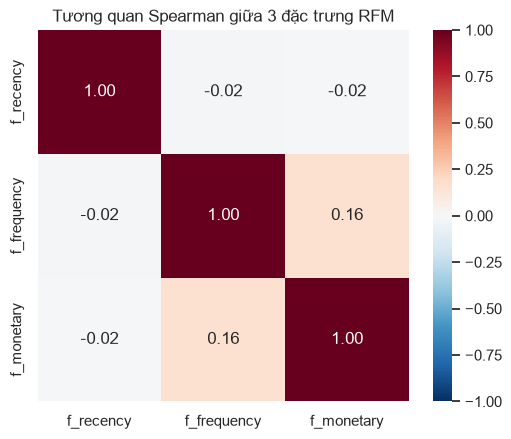

In [3]:
feat = pd.DataFrame({
    "f_recency": df["recency_days"],
    "f_frequency": np.log1p(df["frequency"]),
    "f_monetary": np.log1p(df["monetary"]),
})
FEATURES = list(feat.columns)

skew = pd.DataFrame({
    "skew_truoc": [df["recency_days"].skew(), df["frequency"].skew(), df["monetary"].skew()],
    "skew_sau": [feat[c].skew() for c in FEATURES],
}, index=["recency_days", "frequency", "monetary"])
print("Độ lệch (skewness) trước và sau biến đổi:")
display(skew.round(3))

X = StandardScaler().fit_transform(feat.values)

corr = feat.corr(method="spearman")
display(corr.round(3))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Tương quan Spearman giữa 3 đặc trưng RFM")
plt.tight_layout(); fig.savefig(FIG_DIR / "01_feature_correlation.png", dpi=150); plt.show()

## Bước 3 — Chọn số cụm K
Với K = 2..10: inertia, silhouette (mẫu 10,000), Davies-Bouldin, Calinski-Harabasz và tỷ lệ cụm nhỏ nhất.

**Luật chọn K** (cố định trước khi chạy): chỉ xét K = 3..8; loại K có cụm nhỏ nhất < 2% dân số; chọn K có silhouette cao nhất; nếu nhiều K chênh silhouette < 0.01 so với K tốt nhất thì chọn K nhỏ nhất.

Bảng đánh giá K:


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct
0,2,"190,195.6634",0.7069,0.4757,"44,116.0532",3.0003
1,3,"126,272.1744",0.3597,0.9189,"56,854.9390",3.0003
2,4,"85,767.0286",0.3709,0.7857,"70,500.0813",3.0003
3,5,"70,363.3436",0.3575,0.8384,"69,557.9914",3.0003
4,6,"59,310.5979",0.3450,0.8632,"69,495.0905",3.0003
5,7,"50,725.1748",0.3571,0.7688,"70,347.3820",3.0003
6,8,"45,144.2505",0.3438,0.7932,"69,399.8261",3.0003
7,9,"40,370.4554",0.3445,0.8091,"69,284.8940",0.2442
8,10,"36,521.5797",0.3459,0.8332,"69,169.0339",0.2442


Ứng viên hợp lệ (sắp theo silhouette):


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct
0,4,"85,767.0286",0.3709,0.7857,"70,500.0813",3.0003
1,3,"126,272.1744",0.3597,0.9189,"56,854.9390",3.0003
2,5,"70,363.3436",0.3575,0.8384,"69,557.9914",3.0003
3,7,"50,725.1748",0.3571,0.7688,"70,347.3820",3.0003
4,6,"59,310.5979",0.3450,0.8632,"69,495.0905",3.0003
5,8,"45,144.2505",0.3438,0.7932,"69,399.8261",3.0003


Silhouette cao nhất = 0.3709; các K trong vùng chênh < 0.01: [4]
AUTO_K = 4 | FINAL_K = 4


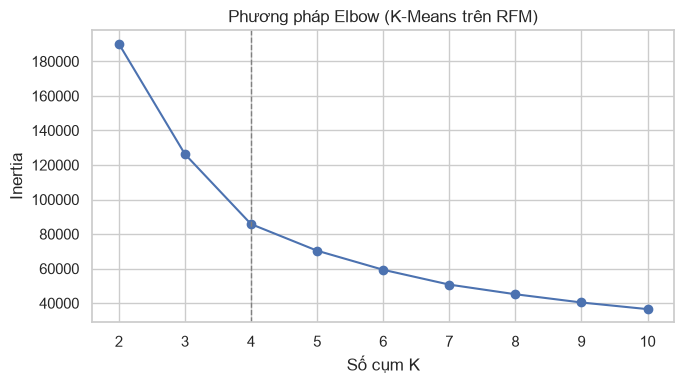

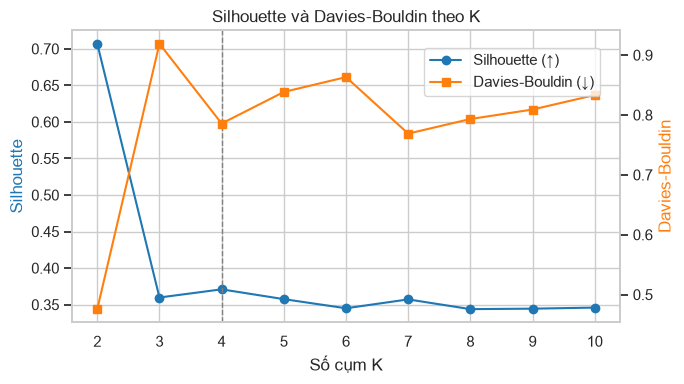

In [4]:
records = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE)
    lab = km.fit_predict(X)
    sizes = np.bincount(lab, minlength=k)
    records.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, lab, sample_size=SIL_SAMPLE, random_state=RANDOM_STATE),
        "davies_bouldin": davies_bouldin_score(X, lab),
        "calinski_harabasz": calinski_harabasz_score(X, lab),
        "min_cluster_pct": 100 * sizes.min() / len(lab),
    })
k_eval = pd.DataFrame(records)
print("Bảng đánh giá K:")
display(k_eval.round(4))

cand = k_eval[k_eval["k"].between(*K_CHOICE_RANGE) & (k_eval["min_cluster_pct"] >= MIN_CLUSTER_PCT)]
cand = cand.sort_values("silhouette", ascending=False).reset_index(drop=True)
best_sil = cand.loc[0, "silhouette"]
close = cand[(best_sil - cand["silhouette"]) < 0.01]
AUTO_K = int(close["k"].min())
FINAL_K_OVERRIDE = None
FINAL_K = FINAL_K_OVERRIDE if FINAL_K_OVERRIDE is not None else AUTO_K

print("Ứng viên hợp lệ (sắp theo silhouette):")
display(cand.round(4))
print(f"Silhouette cao nhất = {best_sil:.4f}; các K trong vùng chênh < 0.01: {close['k'].tolist()}")
print(f"AUTO_K = {AUTO_K} | FINAL_K = {FINAL_K}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_eval["k"], k_eval["inertia"], marker="o")
ax.axvline(FINAL_K, color="grey", ls="--", lw=1)
ax.set(xlabel="Số cụm K", ylabel="Inertia", title="Phương pháp Elbow (K-Means trên RFM)")
plt.tight_layout(); fig.savefig(FIG_DIR / "02_elbow.png", dpi=150); plt.show()

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(k_eval["k"], k_eval["silhouette"], marker="o", color="tab:blue", label="Silhouette (↑)")
ax1.set_xlabel("Số cụm K"); ax1.set_ylabel("Silhouette", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(k_eval["k"], k_eval["davies_bouldin"], marker="s", color="tab:orange", label="Davies-Bouldin (↓)")
ax2.set_ylabel("Davies-Bouldin", color="tab:orange"); ax2.grid(False)
ax1.axvline(FINAL_K, color="grey", ls="--", lw=1)
ax1.set_title("Silhouette và Davies-Bouldin theo K")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.tight_layout(); fig.savefig(FIG_DIR / "03_silhouette_db.png", dpi=150); plt.show()

## Bước 4 — Mô hình cuối và kiểm tra độ ổn định
Huấn luyện với `FINAL_K`, so sánh nhãn với 5 seed khác bằng Adjusted Rand Index (đạt khi trung bình ≥ 0.90). Sau đó đánh số lại cụm theo monetary trung vị giảm dần (cụm 1 = chi tiêu cao nhất) để kết quả tất định.

In [5]:
final_km = KMeans(n_clusters=FINAL_K, n_init=N_INIT, random_state=RANDOM_STATE)
raw_labels = final_km.fit_predict(X)
dist = np.linalg.norm(X - final_km.cluster_centers_[raw_labels], axis=1)

ari = pd.DataFrame({
    "seed": s,
    "ari_vs_seed_42": adjusted_rand_score(
        raw_labels, KMeans(n_clusters=FINAL_K, n_init=N_INIT, random_state=s).fit_predict(X)),
} for s in [0, 1, 2, 3, 4])
display(ari.round(4))
MEAN_ARI = ari["ari_vs_seed_42"].mean()
print(f"Mean ARI = {MEAN_ARI:.4f} ->", "ỔN ĐỊNH" if MEAN_ARI >= ARI_THRESHOLD else "CẢNH BÁO: dưới ngưỡng 0.90")

g0 = pd.DataFrame({"lab": raw_labels, "m": df["monetary"].values, "r": df["recency_days"].values})
order = (g0.groupby("lab").agg(m=("m", "median"), r=("r", "median"))
         .sort_values(["m", "r"], ascending=[False, True]).index.tolist())
remap = {old: new for new, old in enumerate(order, start=1)}
df["cluster_id"] = pd.Series(raw_labels).map(remap).values
df["distance_to_centroid"] = dist
print("Kích thước cụm:")
display(df["cluster_id"].value_counts().sort_index().to_frame("n_customers"))

,seed,ari_vs_seed_42
0,0,0.9767
1,1,0.9928
2,2,0.9935
3,3,0.9992
4,4,0.9853


Mean ARI = 0.9895 -> ỔN ĐỊNH
Kích thước cụm:


,n_customers
cluster_id,
1,2801
2,27585
3,27014
4,35958


## Bước 5 — Chân dung, nhãn và mô tả cụm
Nhãn sinh tự động theo luật, so chân dung cụm với toàn bộ khách:
- Cụm có ≥ 50% khách mua từ 2 đơn → **"Mua lặp"**;
- ngược lại ghép 2 vế: Recency trung vị < trung vị chung → **"Mới mua"**, ngược lại **"Lâu chưa mua"**; Monetary trung vị ≥ trung vị chung → **"chi cao"**, ngược lại **"chi thấp"**.

Mỗi nhãn có tiền tố `C<cluster_id>` để luôn duy nhất. Review và tỷ lệ giao trễ chỉ để mô tả, không tham gia phân cụm.

Toàn bộ: recency trung vị = 218 ngày | monetary trung vị = 107.78 BRL | repeat rate = 0.0300 | review TB = 4.15 | late rate = 0.0811


,cluster_id,n_customers,pct_customers,sum_monetary,pct_monetary,median_recency_days,mean_frequency,repeat_rate,median_monetary,mean_monetary,avg_review_score,late_order_rate,top_state,pct_top_state,cluster_label
0,1,2801,3.0000,"864,187.4600",5.6040,199.0000,2.1140,1.0000,225.5500,308.5280,4.2070,0.0700,SP,43.6990,C1 · Mua lặp
1,2,27585,29.5480,"8,855,497.1400",57.4290,171.0000,1.0000,0.0000,212.8300,321.0260,4.0350,0.1020,SP,36.8240,C2 · Mới mua · chi cao
2,3,27014,28.9360,"3,188,980.2900",20.6810,417.0000,1.0000,0.0000,97.6350,118.0490,4.2180,0.0500,SP,39.0580,C3 · Lâu chưa mua · chi thấp
3,4,35958,38.5160,"2,511,108.8600",16.2850,146.0000,1.0000,0.0000,66.6400,69.8340,4.1920,0.0910,SP,47.8810,C4 · Mới mua · chi thấp


C1 · Mua lặp: 2,801 khách (3.0%), đóng góp 5.6% tổng chi tiêu. Lần mua cuối cách snapshot 199 ngày (trung vị); chi tiêu trung vị 225.55 BRL; trung bình 2.11 đơn, 100.0% khách mua từ 2 đơn. Review TB 4.21, tỷ lệ đơn giao trễ 7.0%.
C2 · Mới mua · chi cao: 27,585 khách (29.5%), đóng góp 57.4% tổng chi tiêu. Lần mua cuối cách snapshot 171 ngày (trung vị); chi tiêu trung vị 212.83 BRL; trung bình 1.00 đơn, 0.0% khách mua từ 2 đơn. Review TB 4.03, tỷ lệ đơn giao trễ 10.2%.
C3 · Lâu chưa mua · chi thấp: 27,014 khách (28.9%), đóng góp 20.7% tổng chi tiêu. Lần mua cuối cách snapshot 417 ngày (trung vị); chi tiêu trung vị 97.63 BRL; trung bình 1.00 đơn, 0.0% khách mua từ 2 đơn. Review TB 4.22, tỷ lệ đơn giao trễ 5.0%.
C4 · Mới mua · chi thấp: 35,958 khách (38.5%), đóng góp 16.3% tổng chi tiêu. Lần mua cuối cách snapshot 146 ngày (trung vị); chi tiêu trung vị 66.64 BRL; trung bình 1.00 đơn, 0.0% khách mua từ 2 đơn. Review TB 4.19, tỷ lệ đơn giao trễ 9.1%.


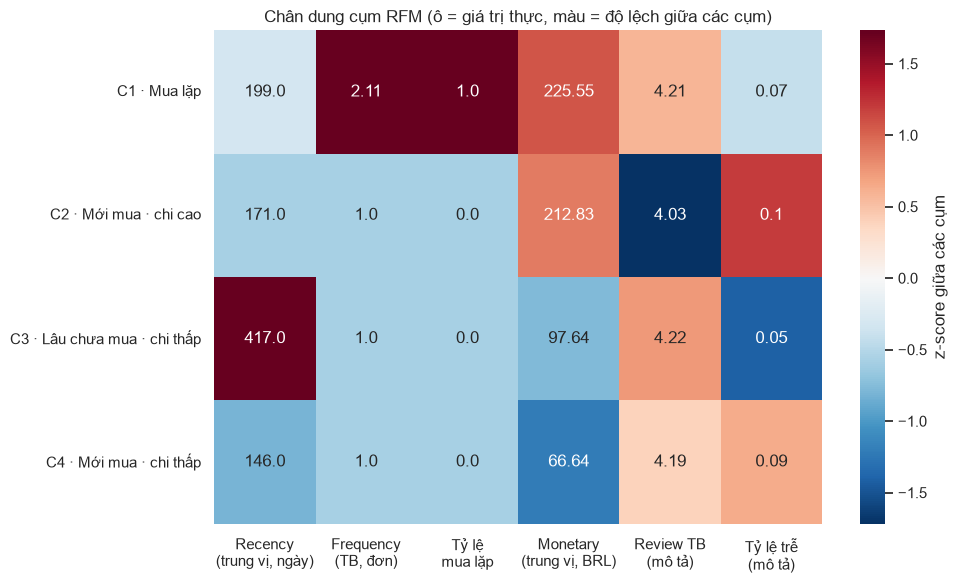

In [6]:
pop_med_r = df["recency_days"].median()
pop_med_m = df["monetary"].median()
total_m = df["monetary"].sum()

def top_state(s):
    vc = s.dropna().value_counts()
    return pd.Series({"top_state": vc.index[0], "pct_top_state": 100 * vc.iloc[0] / vc.sum()})

g = df.groupby("cluster_id")
profile = pd.DataFrame({
    "n_customers": g.size(),
    "pct_customers": 100 * g.size() / len(df),
    "sum_monetary": g["monetary"].sum(),
    "pct_monetary": 100 * g["monetary"].sum() / total_m,
    "median_recency_days": g["recency_days"].median(),
    "mean_frequency": g["frequency"].mean(),
    "repeat_rate": g["frequency"].apply(lambda s: (s > 1).mean()),
    "median_monetary": g["monetary"].median(),
    "mean_monetary": g["monetary"].mean(),
    "avg_review_score": g["avg_review_score"].mean(),
    "late_order_rate": g["orders_late"].sum() / (g["orders_on_time"].sum() + g["orders_late"].sum()),
}).join(g["latest_state"].apply(top_state).unstack())
profile["pct_top_state"] = profile["pct_top_state"].astype(float)

def make_label(cid, row):
    if row["repeat_rate"] >= 0.5:
        name = "Mua lặp"
    else:
        r = "Mới mua" if row["median_recency_days"] < pop_med_r else "Lâu chưa mua"
        m = "chi cao" if row["median_monetary"] >= pop_med_m else "chi thấp"
        name = f"{r} · {m}"
    return f"C{cid} · {name}"

def make_description(row):
    return (f"{int(row['n_customers']):,} khách ({row['pct_customers']:.1f}%), đóng góp {row['pct_monetary']:.1f}% tổng chi tiêu. "
            f"Lần mua cuối cách snapshot {row['median_recency_days']:.0f} ngày (trung vị); "
            f"chi tiêu trung vị {row['median_monetary']:,.2f} BRL; trung bình {row['mean_frequency']:.2f} đơn, "
            f"{100 * row['repeat_rate']:.1f}% khách mua từ 2 đơn. "
            f"Review TB {row['avg_review_score']:.2f}, tỷ lệ đơn giao trễ {100 * row['late_order_rate']:.1f}%.")

profile["cluster_label"] = [make_label(cid, row) for cid, row in profile.iterrows()]
profile["cluster_description"] = [make_description(row) for _, row in profile.iterrows()]
profile = profile.reset_index()
assert profile["cluster_label"].is_unique
df["cluster_label"] = df["cluster_id"].map(dict(zip(profile["cluster_id"], profile["cluster_label"])))

late_all = df["orders_late"].sum() / (df["orders_on_time"].sum() + df["orders_late"].sum())
print(f"Toàn bộ: recency trung vị = {pop_med_r:.0f} ngày | monetary trung vị = {pop_med_m:.2f} BRL | "
      f"repeat rate = {(df['frequency'] > 1).mean():.4f} | review TB = {df['avg_review_score'].mean():.2f} | late rate = {late_all:.4f}")
display(profile.drop(columns="cluster_description").round(3))
for _, r in profile.iterrows():
    print(f"{r['cluster_label']}: {r['cluster_description']}")

hm_cols = {"median_recency_days": "Recency\n(trung vị, ngày)", "mean_frequency": "Frequency\n(TB, đơn)",
           "repeat_rate": "Tỷ lệ\nmua lặp", "median_monetary": "Monetary\n(trung vị, BRL)",
           "avg_review_score": "Review TB\n(mô tả)", "late_order_rate": "Tỷ lệ trễ\n(mô tả)"}
hm = profile.set_index("cluster_label")[list(hm_cols)].rename(columns=hm_cols)
hz = (hm - hm.mean()) / hm.std(ddof=0).replace(0, 1)
fig, ax = plt.subplots(figsize=(10, 1.1 * FINAL_K + 1.6))
sns.heatmap(hz, annot=hm.round(2), fmt="", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "z-score giữa các cụm"})
ax.set(title="Chân dung cụm RFM (ô = giá trị thực, màu = độ lệch giữa các cụm)", xlabel="", ylabel="")
plt.xticks(rotation=0)
plt.tight_layout(); fig.savefig(FIG_DIR / "04_cluster_profile_heatmap.png", dpi=150); plt.show()

### Các cụm trên mặt phẳng Recency × Monetary và tỷ trọng khách / chi tiêu theo cụm

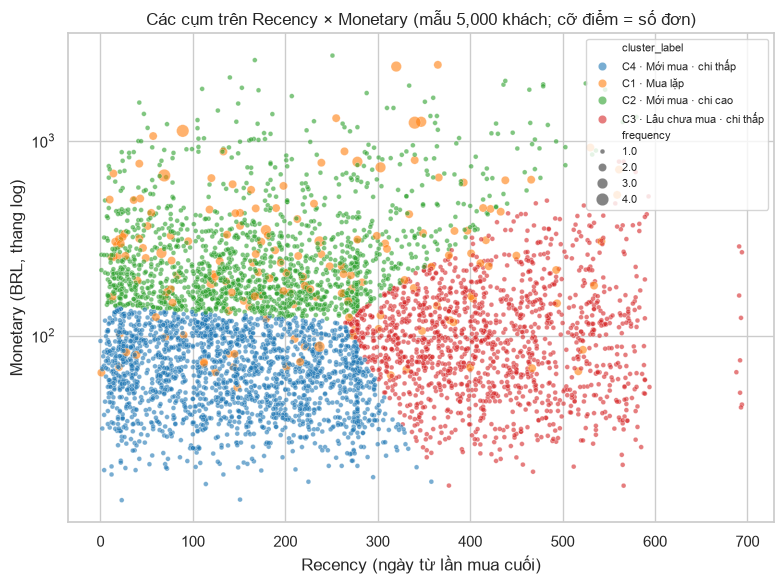

,% khách hàng,% tổng chi tiêu (monetary)
cluster_label,,
C1 · Mua lặp,3.0000,5.6000
C2 · Mới mua · chi cao,29.5500,57.4300
C3 · Lâu chưa mua · chi thấp,28.9400,20.6800
C4 · Mới mua · chi thấp,38.5200,16.2800


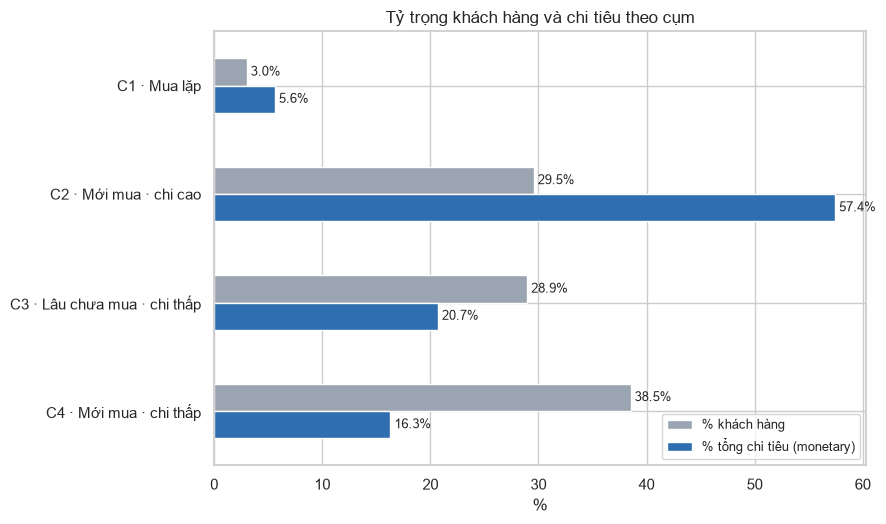

In [7]:
idx = np.random.RandomState(RANDOM_STATE).choice(len(df), 5000, replace=False)
samp = df.iloc[idx]
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=samp, x="recency_days", y="monetary", hue="cluster_label",
                size=samp["frequency"].clip(upper=4), sizes=(12, 80), alpha=0.6, ax=ax, palette="tab10")
ax.set_yscale("log")
ax.set(xlabel="Recency (ngày từ lần mua cuối)", ylabel="Monetary (BRL, thang log)",
       title="Các cụm trên Recency × Monetary (mẫu 5,000 khách; cỡ điểm = số đơn)")
ax.legend(fontsize=8, loc="best")
plt.tight_layout(); fig.savefig(FIG_DIR / "05_cluster_scatter.png", dpi=150); plt.show()

share = profile.set_index("cluster_label")[["pct_customers", "pct_monetary"]]
share.columns = ["% khách hàng", "% tổng chi tiêu (monetary)"]
display(share.round(2))
fig, ax = plt.subplots(figsize=(9, 0.9 * FINAL_K + 1.8))
share.plot.barh(ax=ax, color=["#9aa5b1", "#2f6fb0"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f%%", padding=3, fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="%", ylabel="", title="Tỷ trọng khách hàng và chi tiêu theo cụm")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); fig.savefig(FIG_DIR / "06_cluster_share.png", dpi=150); plt.show()

## Bước 6 — Phân tích độ nhạy: bỏ `frequency`
Huấn luyện lại chỉ với Recency và Monetary (cùng K) để thấy vai trò của Frequency trong cấu trúc cụm. Kết quả không ghi ra MotherDuck.

In [8]:
X_rm = StandardScaler().fit_transform(feat[["f_recency", "f_monetary"]].values)
lab_rm = KMeans(n_clusters=FINAL_K, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(X_rm)
sil_rfm = silhouette_score(X, raw_labels, sample_size=SIL_SAMPLE, random_state=RANDOM_STATE)
sil_rm = silhouette_score(X_rm, lab_rm, sample_size=SIL_SAMPLE, random_state=RANDOM_STATE)
sens = (pd.DataFrame({"cluster": lab_rm, "is_repeat": (df["frequency"] > 1).values})
        .groupby("cluster").agg(n_customers=("is_repeat", "size"), repeat_rate=("is_repeat", "mean")))
sens["pct_customers"] = 100 * sens["n_customers"] / len(df)
display(sens.round(4))
print(f"Silhouette RFM (3 biến) = {sil_rfm:.4f} | chỉ R + M = {sil_rm:.4f}")
print(f"ARI(RFM, R+M) = {adjusted_rand_score(raw_labels, lab_rm):.4f}")

,n_customers,repeat_rate,pct_customers
cluster,,,
0,29676,0.0403,31.7873
1,25401,0.0175,27.2082
2,12709,0.0822,13.6132
3,25572,0.0045,27.3913


Silhouette RFM (3 biến) = 0.3709 | chỉ R + M = 0.3473
ARI(RFM, R+M) = 0.5561


## Bước 7 — Ghi kết quả về MotherDuck (schema `ml`)

In [9]:
MODEL_RUN_TS = pd.Timestamp(datetime.now().replace(microsecond=0))

out_customer = pd.DataFrame({
    "customer_unique_id": df["customer_unique_id"],
    "cluster_id": df["cluster_id"].astype("int32"),
    "cluster_label": df["cluster_label"],
    "distance_to_centroid": df["distance_to_centroid"].astype(float),
    "k": np.int32(FINAL_K),
    "feature_set_version": FEATURE_SET_VERSION,
    "snapshot_date": pd.Timestamp(SNAPSHOT_DATE),
    "model_run_ts": MODEL_RUN_TS,
})
out_profile = profile[["cluster_id", "cluster_label", "cluster_description", "n_customers", "pct_customers",
                       "sum_monetary", "pct_monetary", "median_recency_days", "mean_frequency", "repeat_rate",
                       "median_monetary", "mean_monetary", "avg_review_score", "late_order_rate",
                       "top_state", "pct_top_state"]].copy()
out_profile["k"] = FINAL_K
out_profile["feature_set_version"] = FEATURE_SET_VERSION
out_profile["model_run_ts"] = MODEL_RUN_TS
out_sel = k_eval.copy()
out_sel["is_selected"] = out_sel["k"] == FINAL_K
out_sel["feature_set_version"] = FEATURE_SET_VERSION
out_sel["model_run_ts"] = MODEL_RUN_TS

con.execute(f"CREATE SCHEMA IF NOT EXISTS {OUT_SCHEMA}")
for name, frame, cast in [
    ("customer_cluster", out_customer,
     "customer_unique_id, CAST(cluster_id AS INTEGER) AS cluster_id, cluster_label, distance_to_centroid, "
     "CAST(k AS INTEGER) AS k, feature_set_version, CAST(snapshot_date AS DATE) AS snapshot_date, "
     "CAST(model_run_ts AS TIMESTAMP) AS model_run_ts"),
    ("cluster_profile", out_profile,
     "* REPLACE (CAST(cluster_id AS INTEGER) AS cluster_id, CAST(n_customers AS INTEGER) AS n_customers, "
     "CAST(k AS INTEGER) AS k, CAST(model_run_ts AS TIMESTAMP) AS model_run_ts)"),
    ("kmeans_model_selection", out_sel,
     "* REPLACE (CAST(k AS INTEGER) AS k, CAST(model_run_ts AS TIMESTAMP) AS model_run_ts)"),
]:
    con.register("tmp_df", frame)
    con.execute(f"CREATE OR REPLACE TABLE {OUT_SCHEMA}.{name} AS SELECT {cast} FROM tmp_df")
    con.unregister("tmp_df")
    print(f"Đã ghi {OUT_SCHEMA}.{name}: {len(frame):,} dòng")

Đã ghi ml.customer_cluster: 93,358 dòng


Đã ghi ml.cluster_profile: 4 dòng


Đã ghi ml.kmeans_model_selection: 9 dòng


## Bước 8 — Đọc lại từ MotherDuck và kiểm tra

In [10]:
sel_db = con.execute(f"SELECT * FROM {OUT_SCHEMA}.kmeans_model_selection ORDER BY k").df()
prof_db = con.execute(f"SELECT * EXCLUDE (cluster_description) FROM {OUT_SCHEMA}.cluster_profile ORDER BY cluster_id").df()
cc_db = con.execute(f"""
    SELECT k, feature_set_version, COUNT(*) AS n, COUNT(DISTINCT customer_unique_id) AS n_unique,
           COUNT(DISTINCT cluster_id) AS n_clusters, MIN(cluster_id) AS min_id, MAX(cluster_id) AS max_id,
           MIN(model_run_ts) AS ts_min, MAX(model_run_ts) AS ts_max
    FROM {OUT_SCHEMA}.customer_cluster GROUP BY 1, 2""").df()
display(sel_db); display(prof_db); display(cc_db)

assert len(cc_db) == 1
r = cc_db.iloc[0]
assert r["n"] == EXPECTED_ROWS and r["n_unique"] == EXPECTED_ROWS
assert r["n_clusters"] == FINAL_K and r["min_id"] == 1 and r["max_id"] == FINAL_K
assert r["ts_min"] == r["ts_max"]
assert prof_db["n_customers"].sum() == EXPECTED_ROWS
assert abs(prof_db["pct_monetary"].sum() - 100) < 0.01
assert sel_db["is_selected"].sum() == 1
print("Tất cả kiểm tra đạt. Bước tiếp theo: dbt build mart_customer_rfm + dim_customer_cluster.")

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct,is_selected,feature_set_version,model_run_ts
0,2,"190,195.6634",0.7069,0.4757,"44,116.0532",3.0003,False,rfm_v1,2026-11-04 10:09:34
1,3,"126,272.1744",0.3597,0.9189,"56,854.9390",3.0003,False,rfm_v1,2026-11-04 10:09:34
2,4,"85,767.0286",0.3709,0.7857,"70,500.0813",3.0003,True,rfm_v1,2026-11-04 10:09:34
3,5,"70,363.3436",0.3575,0.8384,"69,557.9914",3.0003,False,rfm_v1,2026-11-04 10:09:34
4,6,"59,310.5979",0.3450,0.8632,"69,495.0905",3.0003,False,rfm_v1,2026-11-04 10:09:34
5,7,"50,725.1748",0.3571,0.7688,"70,347.3820",3.0003,False,rfm_v1,2026-11-04 10:09:34
6,8,"45,144.2505",0.3438,0.7932,"69,399.8261",3.0003,False,rfm_v1,2026-11-04 10:09:34
7,9,"40,370.4554",0.3445,0.8091,"69,284.8940",0.2442,False,rfm_v1,2026-11-04 10:09:34
8,10,"36,521.5797",0.3459,0.8332,"69,169.0339",0.2442,False,rfm_v1,2026-11-04 10:09:34


,cluster_id,cluster_label,n_customers,pct_customers,sum_monetary,pct_monetary,median_recency_days,mean_frequency,repeat_rate,median_monetary,mean_monetary,avg_review_score,late_order_rate,top_state,pct_top_state,k,feature_set_version,model_run_ts
0,1,C1 · Mua lặp,2801,3.0003,"864,187.4600",5.6044,199.0000,2.1139,1.0000,225.5500,308.5282,4.2065,0.0698,SP,43.6987,4,rfm_v1,2026-11-04 10:09:34
1,2,C2 · Mới mua · chi cao,27585,29.5475,"8,855,497.1400",57.4295,171.0000,1.0000,0.0000,212.8300,321.0258,4.0349,0.1017,SP,36.8244,4,rfm_v1,2026-11-04 10:09:34
2,3,C3 · Lâu chưa mua · chi thấp,27014,28.9359,"3,188,980.2900",20.6811,417.0000,1.0000,0.0000,97.6350,118.0492,4.2185,0.0500,SP,39.0575,4,rfm_v1,2026-11-04 10:09:34
3,4,C4 · Mới mua · chi thấp,35958,38.5162,"2,511,108.8600",16.2850,146.0000,1.0000,0.0000,66.6400,69.8345,4.1919,0.0905,SP,47.8809,4,rfm_v1,2026-11-04 10:09:34


,k,feature_set_version,n,n_unique,n_clusters,min_id,max_id,ts_min,ts_max
0,4,rfm_v1,93358,93358,4,1,4,2026-11-04 10:09:34,2026-11-04 10:09:34


Tất cả kiểm tra đạt. Bước tiếp theo: dbt build mart_customer_rfm + dim_customer_cluster.


## Tóm tắt

In [11]:
sel_row = k_eval.set_index("k").loc[FINAL_K]
print(f"Đặc trưng           : recency_days, log1p(frequency), log1p(monetary) -> StandardScaler")
print(f"K được chọn          : {FINAL_K} (AUTO_K = {AUTO_K}, override = {FINAL_K_OVERRIDE})")
print(f"Silhouette (mẫu 10k) : {sel_row['silhouette']:.4f}")
print(f"Davies-Bouldin       : {sel_row['davies_bouldin']:.4f}")
print(f"Mean ARI (5 seed)    : {MEAN_ARI:.4f}")
print(f"model_run_ts         : {MODEL_RUN_TS}")
print("Hình đã lưu:", sorted(p.name for p in FIG_DIR.glob("*.png")))
con.close()

Đặc trưng           : recency_days, log1p(frequency), log1p(monetary) -> StandardScaler
K được chọn          : 4 (AUTO_K = 4, override = None)
Silhouette (mẫu 10k) : 0.3709
Davies-Bouldin       : 0.7857
Mean ARI (5 seed)    : 0.9895
model_run_ts         : 2026-11-04 10:09:34
Hình đã lưu: ['01_feature_correlation.png', '02_elbow.png', '03_silhouette_db.png', '04_cluster_profile_heatmap.png', '05_cluster_scatter.png', '06_cluster_share.png']
